# 07 System Integration

Extracted from `FP_NewsBot2_ksm_GroupName_ITAI2373.ipynb` (original outputs kept). Complete NewsBot 2.0 final-project pipeline (all modules A-D + integration + demo). Requires the midterm `newsbot_dataset.csv` or `BBC News Train.csv` in the working directory.

Upload `BBC News Train.csv` (in `data/raw/`) to Colab before running.

---
# 🚀 FINAL PROJECT: NewsBot Intelligence System 2.0
### ITAI 2373 – Final Project

**Team Members:** khalida Bestani, Sadea Saeed, Marisabel Morales
**Submitted by:** ksm | **Group:** GroupName
**GitHub Repository:** [Add your repo URL here]

Everything above this cell is our midterm (we kept it so you can see where we started).
From here on we add the four new modules from the final project guidelines:

| Module | What we built |
|---|---|
| **A. Advanced Content Analysis** | tuned classifier with confidence + top-2 categories, LDA & NMF topic modeling, topic "evolution", article clustering, sentiment evolution, entity relationship mapping |
| **B. Language Understanding & Generation** | extractive summarization (TextRank), semantic search with query expansion, content enhancement, automatic insights |
| **C. Multilingual Intelligence** | language detection (langdetect), translation (deep-translator with fallback), cross-language comparison |
| **D. Conversational Interface** | intent classifier, multi-part questions, conversation memory, response generator |

We tried to keep the code simple so all of us could understand it. The same code is also in our GitHub repo as separate Python files (`src/` folder).

## 📦 Final Project Setup
We need two extra libraries for the multilingual part. The cell also makes sure the dataset is loaded
(the same `newsbot_dataset.csv` we made in the midterm from the Kaggle **BBC News Train.csv**), so the
final-project part can run even after a Colab restart.

In [1]:
!pip install -q langdetect deep-translator

import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

# Load the dataset the same way as the midterm (Kaggle 'BBC News Train.csv' -> newsbot_dataset.csv)
if 'df' not in globals() or 'content' not in df.columns or len(df) < 1000:
    if os.path.exists('newsbot_dataset.csv'):
        df = pd.read_csv('newsbot_dataset.csv')
    else:
        df = pd.read_csv('BBC News Train.csv').rename(
            columns={'ArticleId': 'article_id', 'Text': 'content', 'Category': 'category'})
df = df[['article_id', 'content', 'category']].dropna().reset_index(drop=True)
print('Articles:', len(df))
print(df['category'].value_counts())

Articles: 1490
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


In [2]:
# Preprocessing functions (same steps as our midterm, plus a sentence splitter for summaries)
"""Text cleaning and preprocessing (enhanced from our midterm)."""
import re
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "vader_lexicon"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

_lemmatizer = WordNetLemmatizer()
_stop_words = set(stopwords.words("english"))


def clean_text(text):
    """Lowercase, remove HTML, URLs, emails, numbers and symbols."""
    if text is None:
        return ""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return re.sub(r"\s+", " ", text).strip()


def preprocess_text(text):
    """Clean + remove stop words + lemmatize + drop very short words."""
    tokens = clean_text(text).split()
    tokens = [_lemmatizer.lemmatize(t) for t in tokens if t not in _stop_words]
    return " ".join(t for t in tokens if len(t) > 2)


def split_sentences(text):
    """Split an article into sentences (BBC text uses '. ' between sentences)."""
    try:
        sents = nltk.sent_tokenize(str(text))
    except Exception:
        sents = re.split(r"(?<=[.!?])\s+", str(text))
    return [s.strip() for s in sents if len(s.split()) >= 4]

df['processed'] = df['content'].apply(preprocess_text)
print('Preprocessing done. Example:', df['processed'][0][:120])

Preprocessing done. Example: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company 


### 🧪 Data quality check (new)
While building the final project we found something we missed in the midterm: some articles in the BBC
training file are **exact duplicates**. If the same article is in both train and test, the accuracy looks
better than it really is. So we count them and remove them for the final project models.

In [3]:
"""Data quality checks before analysis."""
import logging
import pandas as pd

log = logging.getLogger(__name__)
REQUIRED = ["article_id", "content", "category"]


def _load_bbc_unused(path):
    """Load the Kaggle 'BBC News Train.csv' and rename columns like the midterm."""
    df = pd.read_csv(path)
    df = df.rename(columns={"ArticleId": "article_id", "Text": "content", "Category": "category"})
    return validate(df)


def validate(df):
    """Drop missing/empty/duplicate articles and print a short report."""
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    before = len(df)
    df = df.dropna(subset=["content", "category"])
    df = df[df["content"].str.strip().str.len() > 0]
    n_dup = int(df.duplicated(subset="content").sum())
    df = df.drop_duplicates(subset="content").reset_index(drop=True)
    report = {"rows_in": before, "rows_out": len(df), "duplicates_removed": n_dup,
              "categories": df["category"].value_counts().to_dict()}
    log.info("Data validation: %s", report)
    df.attrs["validation_report"] = report
    return df

df_full = df.copy()                 # midterm version (1490 articles)
df = validate(df)                   # final project version (duplicates removed)
print(df.attrs['validation_report'])

{'rows_in': 1490, 'rows_out': 1440, 'duplicates_removed': 50, 'categories': {'sport': 342, 'business': 335, 'politics': 266, 'entertainment': 263, 'tech': 234}}


---
## 🅰️ Module A: Advanced Content Analysis Engine

### A1. Enhanced Classification with Confidence Scores
In the midterm our best model was Logistic Regression with **97.65%** test accuracy. For the final project we:
- put TF-IDF and the model into one **scikit-learn Pipeline** (so new text can be classified directly),
- use `sublinear_tf=True` and a small **grid search** for the C parameter,
- compare Naive Bayes, Logistic Regression and Linear SVM again,
- return a **confidence score** and the **top-2 categories** ("multi-level" output).

In [4]:
TFIDF_PARAMS = dict(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)

"""Module A: enhanced classification with confidence scores."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, classification_report, f1_score


def make_pipeline(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)),
        ("clf", model),
    ])


class NewsClassifier:
    """TF-IDF + Logistic Regression, tuned with a small grid search."""

    def __init__(self):
        self.model = None
        self.results = {}

    def compare_models(self, X_train, y_train, X_test, y_test):
        models = {
            "Naive Bayes": MultinomialNB(),
            "Logistic Regression": LogisticRegression(max_iter=2000),
            "Linear SVM": LinearSVC(),
        }
        for name, m in models.items():
            pipe = make_pipeline(m).fit(X_train, y_train)
            pred = pipe.predict(X_test)
            self.results[name] = {
                "accuracy": accuracy_score(y_test, pred),
                "macro_f1": f1_score(y_test, pred, average="macro"),
            }
        return self.results

    def fit(self, X_train, y_train, tune=True):
        pipe = make_pipeline(LogisticRegression(max_iter=2000))
        if tune:
            grid = GridSearchCV(pipe, {"clf__C": [1, 5, 10, 20]}, cv=3, n_jobs=-1)
            grid.fit(X_train, y_train)
            self.model = grid.best_estimator_
            self.best_params = grid.best_params_
        else:
            self.model = pipe.fit(X_train, y_train)
            self.best_params = {}
        return self

    def evaluate(self, X_test, y_test):
        pred = self.model.predict(X_test)
        return accuracy_score(y_test, pred), classification_report(y_test, pred)

    def predict(self, texts):
        return self.model.predict(texts)

    def predict_top_k(self, text, k=2):
        """Multi-level output: the top-k categories with probabilities."""
        probs = self.model.predict_proba([text])[0]
        order = np.argsort(probs)[::-1][:k]
        return [(self.model.classes_[i], float(probs[i])) for i in order]

    def save(self, path):
        import joblib
        joblib.dump(self.model, path)

    def load(self, path):
        import joblib
        self.model = joblib.load(path)
        return self

    def predict_with_confidence(self, text):
        probs = self.model.predict_proba([text])[0]
        i = int(np.argmax(probs))
        return self.model.classes_[i], float(probs[i])

Model comparison (duplicates removed):
                     accuracy  macro_f1
Naive Bayes            0.9479    0.9448
Logistic Regression    0.9583    0.9559
Linear SVM             0.9618    0.9605



Best C: {'clf__C': 10}
Tuned Logistic Regression accuracy: 0.9653
               precision    recall  f1-score   support

     business       0.96      0.97      0.96        67
entertainment       0.96      0.98      0.97        53
     politics       0.96      0.94      0.95        53
        sport       0.97      1.00      0.99        68
         tech       0.98      0.91      0.95        47

     accuracy                           0.97       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.97      0.97      0.97       288



Same model on the 1490-article midterm data (with duplicates): 0.9765


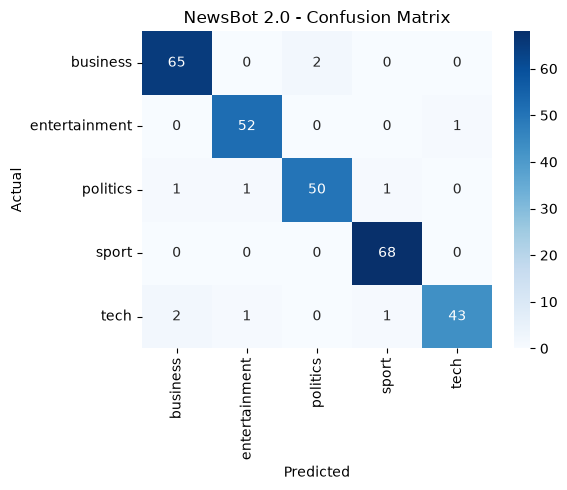

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    df['processed'], df['category'], test_size=0.2, random_state=42, stratify=df['category'])

news_clf = NewsClassifier()
comparison = pd.DataFrame(news_clf.compare_models(X_train, y_train, X_test, y_test)).T
print('Model comparison (duplicates removed):')
print(comparison.round(4))

news_clf.fit(X_train, y_train, tune=True)
final_acc, final_report = news_clf.evaluate(X_test, y_test)
print('\nBest C:', news_clf.best_params)
print(f'Tuned Logistic Regression accuracy: {final_acc:.4f}')
print(final_report)

# Same pipeline on the midterm data WITH duplicates, to compare fairly with the midterm number
Xa, Xb, ya, yb = train_test_split(df_full['content'].apply(preprocess_text), df_full['category'],
                                  test_size=0.2, random_state=42, stratify=df_full['category'])
acc_with_dups = NewsClassifier().fit(Xa, ya, tune=True).evaluate(Xb, yb)[0]
print(f'Same model on the 1490-article midterm data (with duplicates): {acc_with_dups:.4f}')

cm = confusion_matrix(y_test, news_clf.predict(X_test), labels=news_clf.model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=news_clf.model.classes_, yticklabels=news_clf.model.classes_)
plt.title('NewsBot 2.0 - Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()

In [6]:
# Confidence scores and top-2 categories for new articles
examples = [
    "The striker scored twice as the club won the cup final in front of 60,000 fans.",
    "Shares fell sharply after the central bank raised interest rates again.",
    "The new smartphone app lets users stream music and films over broadband.",
    "The minister said the government will publish its election manifesto next week.",
    "The actress won an award for her role in the new film at the festival.",
]
for text in examples:
    p = preprocess_text(text)
    cat, conf = news_clf.predict_with_confidence(p)
    top2 = news_clf.predict_top_k(p, 2)
    print(f'{cat:13s} {conf:.0%} | top-2: {[(c, round(s, 2)) for c, s in top2]} | {text[:55]}...')

sport         93% | top-2: [('sport', 0.93), ('entertainment', 0.03)] | The striker scored twice as the club won the cup final ...
business      93% | top-2: [('business', 0.93), ('entertainment', 0.03)] | Shares fell sharply after the central bank raised inter...
entertainment 53% | top-2: [('entertainment', 0.53), ('tech', 0.41)] | The new smartphone app lets users stream music and film...
politics      80% | top-2: [('politics', 0.8), ('business', 0.1)] | The minister said the government will publish its elect...
entertainment 99% | top-2: [('entertainment', 0.99), ('business', 0.0)] | The actress won an award for her role in the new film a...


**What we see:** The tuned model is about as accurate as our midterm model, but now it also tells us *how sure*
it is. Short sentences get lower confidence than full articles, which makes sense because there are fewer words
to use. The top-2 output is useful for articles that mix topics (for example a business story about a tech company).

### A2. Topic Discovery with LDA and NMF
Classification only uses the 5 labels we already know. Topic modeling is **unsupervised**: it finds groups of words
that appear together, without using the labels. We tried both methods from class:
- **LDA** (Latent Dirichlet Allocation) on word counts
- **NMF** (Non-negative Matrix Factorization) on TF-IDF

Then we check if the topics match the real categories (we call this *topic purity*).

In [7]:
"""Module A: topic discovery with LDA and NMF."""
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF


class TopicModeler:
    def __init__(self, n_topics=5, method="nmf", random_state=42):
        self.n_topics = n_topics
        self.method = method
        if method == "lda":
            self.vectorizer = CountVectorizer(max_features=3000, min_df=5, max_df=0.7)
            self.model = LatentDirichletAllocation(n_components=n_topics, random_state=random_state, learning_method="batch")
        else:
            self.vectorizer = TfidfVectorizer(max_features=3000, min_df=5, max_df=0.7)
            self.model = NMF(n_components=n_topics, random_state=random_state, init="nndsvd", max_iter=400)

    def fit(self, processed_texts):
        self.dtm = self.vectorizer.fit_transform(processed_texts)
        self.doc_topics = self.model.fit_transform(self.dtm)
        return self

    def fit_transform(self, documents):
        """Train topic model and return the document-topic matrix."""
        return self.fit(documents).doc_topics

    def get_topic_words(self, topic_id, n_words=10):
        return self.top_words(n_words)[f"Topic {topic_id}"]

    def topic_evolution(self, periods):
        """Share of each dominant topic per period (topic trend over 'time')."""
        return pd.crosstab(pd.Series(list(periods), name="period"),
                           pd.Series(self.dominant_topic(), name="topic"), normalize="index")

    def cluster_articles(self, n_clusters=5, random_state=42):
        """Group similar articles using their topic distributions (KMeans)."""
        from sklearn.cluster import KMeans
        return KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10).fit_predict(self.doc_topics)

    def visualize_topics(self, n_words=8, save_path=None):
        """Bar charts of the top words for each topic."""
        import matplotlib.pyplot as plt
        words = self.vectorizer.get_feature_names_out()
        fig, axes = plt.subplots(1, self.n_topics, figsize=(3.2 * self.n_topics, 4))
        for k, ax in enumerate(axes):
            comp = self.model.components_[k]
            idx = comp.argsort()[::-1][:n_words]
            ax.barh([words[i] for i in idx][::-1], comp[idx][::-1], color="#4C72B0")
            ax.set_title(f"Topic {k}")
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=120)
        return fig

    def top_words(self, n=10):
        words = self.vectorizer.get_feature_names_out()
        return {f"Topic {k}": [words[i] for i in comp.argsort()[::-1][:n]]
                for k, comp in enumerate(self.model.components_)}

    def dominant_topic(self):
        return self.doc_topics.argmax(axis=1)

    def topic_vs_category(self, categories):
        return pd.crosstab(pd.Series(self.dominant_topic(), name="topic"),
                           pd.Series(list(categories), name="category"))

    def transform(self, processed_texts):
        return self.model.transform(self.vectorizer.transform(processed_texts))


def topic_purity(crosstab):
    """Share of articles that belong to the majority category of their topic."""
    return float(crosstab.max(axis=1).sum() / crosstab.values.sum())


===== LDA topics =====
Topic 0: year, company, market, firm, sale, also, country, would, growth, bank
Topic 1: people, phone, mobile, technology, service, new, also, could, use, would
Topic 2: would, government, labour, election, party, people, say, minister, blair, also
Topic 3: game, first, england, player, win, year, world, time, two, last
Topic 4: film, best, year, award, show, star, one, also, music, new
category  business  entertainment  politics  sport  tech
topic                                                   
0              317              4        11      0     6
1                7              7         1      0   213
2               11             14       252      2     8
3                0              0         1    338     4
4                0            238         1      2     3
Topic purity: 0.943



===== NMF topics =====
Topic 0: growth, economy, market, sale, rate, year, bank, firm, company, share
Topic 1: film, award, best, actor, oscar, star, actress, festival, director, nomination
Topic 2: labour, election, blair, party, tory, brown, tax, government, minister, would
Topic 3: game, england, win, player, match, cup, champion, wale, team, ireland
Topic 4: mobile, phone, people, technology, music, service, user, broadband, net, digital
category  business  entertainment  politics  sport  tech
topic                                                   
0              307              5         4      0     2
1                1            195         0      2     3
2                8              5       249      0     1
3                5             14         8    340     8
4               14             44         5      0   220
Topic purity: 0.910


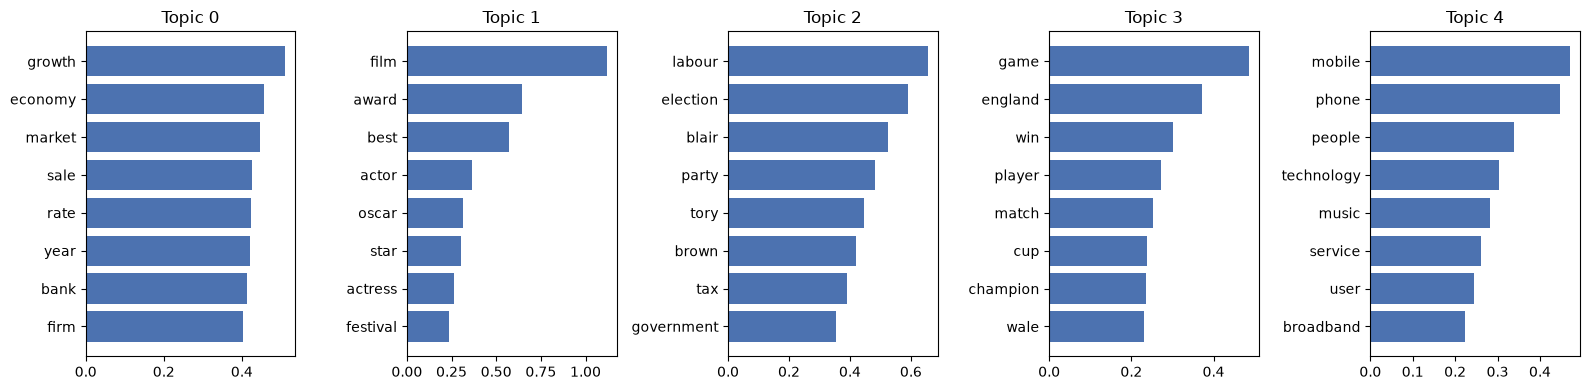

In [8]:
topic_results = {}
for method in ['lda', 'nmf']:
    tm = TopicModeler(n_topics=5, method=method).fit(df['processed'])
    topic_results[method] = tm
    print(f'\n===== {method.upper()} topics =====')
    for k, words in tm.top_words(10).items():
        print(f'{k}: {", ".join(words)}')
    ct = tm.topic_vs_category(df['category'])
    print(ct)
    print(f'Topic purity: {topic_purity(ct):.3f}')

nmf_model = topic_results['nmf']
nmf_model.visualize_topics(n_words=8)
plt.show()

### A3. Topic Evolution, Content Clustering and Sentiment Evolution
The guidelines ask us to track topics and sentiment **over time**. The BBC dataset has **no dates**, so we could
not do real time tracking. As a stand-in we split the articles into 5 "periods" by `article_id` order
(this is **not** real time, it is only to show how the code would work if we had dates).
We also cluster articles with KMeans on their topic mix.

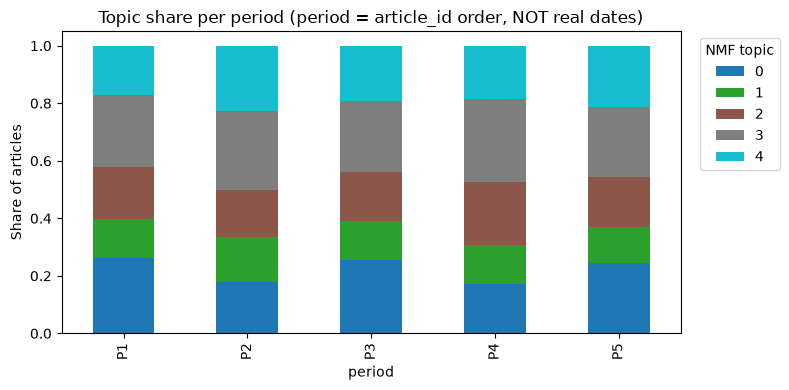

Clusters vs categories:
category  business  entertainment  politics  sport  tech
cluster                                                 
0                1              1         3    327     9
1                3              6         2      0   192
2              329            128        88     14    29
3                2              0       173      0     1
4                0            128         0      1     3


In [9]:
df['period'] = pd.qcut(df['article_id'].rank(method='first'), 5, labels=['P1', 'P2', 'P3', 'P4', 'P5'])

evo = nmf_model.topic_evolution(df['period'])
evo.plot(kind='bar', stacked=True, figsize=(8, 4), colormap='tab10')
plt.title('Topic share per period (period = article_id order, NOT real dates)')
plt.ylabel('Share of articles'); plt.legend(title='NMF topic', bbox_to_anchor=(1.02, 1)); plt.tight_layout(); plt.show()

clusters = nmf_model.cluster_articles(n_clusters=5)
print('Clusters vs categories:')
print(pd.crosstab(pd.Series(clusters, name='cluster'), df['category']))

Average sentiment by category:
category
business         0.2381
entertainment    0.5900
politics         0.0541
sport            0.5492
tech             0.5330
Name: compound, dtype: float64


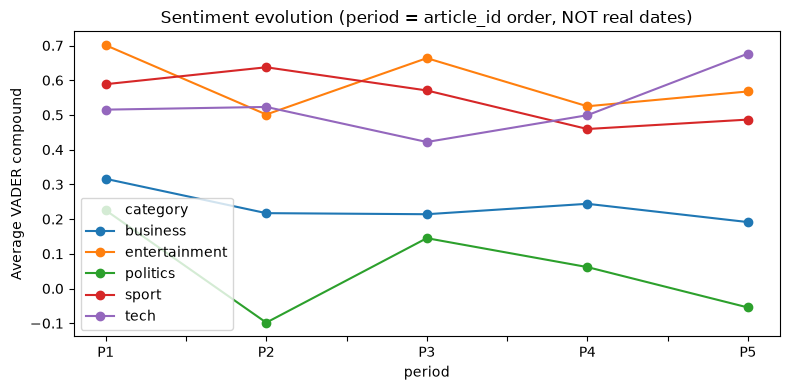

In [10]:
"""Module A: sentiment analysis (VADER, same as midterm) + sentiment evolution."""
import pandas as pd
import nltk
try:
    nltk.download("vader_lexicon", quiet=True)
except Exception:
    pass
from nltk.sentiment import SentimentIntensityAnalyzer


class SentimentAnalyzer:
    """VADER sentiment (same as midterm) with a simple label."""

    def __init__(self):
        self.sia = SentimentIntensityAnalyzer()

    def analyze(self, text):
        s = self.sia.polarity_scores(str(text))
        if s["compound"] >= 0.05:
            s["label"] = "positive"
        elif s["compound"] <= -0.05:
            s["label"] = "negative"
        else:
            s["label"] = "neutral"
        return s

    def analyze_df(self, df, text_col="content"):
        scores = df[text_col].map(self.analyze)
        out = df[["article_id", "category"]].copy()
        out["compound"] = scores.map(lambda s: s["compound"])
        out["label"] = scores.map(lambda s: s["label"])
        return out

    def sentiment_evolution(self, sent_df, time_col="period"):
        """Average sentiment per time period and category.
        NOTE: the BBC dataset has no dates, so we use article_id order split into
        periods as a stand-in for time. With a dated dataset, pass a real date column."""
        return sent_df.groupby([time_col, "category"])["compound"].mean().unstack()


sentiment_tool = SentimentAnalyzer()
sent_df = sentiment_tool.analyze_df(df)
sent_df['period'] = df['period'].values
print('Average sentiment by category:')
print(sent_df.groupby('category')['compound'].mean().round(4))
sentiment_tool.sentiment_evolution(sent_df).plot(marker='o', figsize=(8, 4))
plt.title('Sentiment evolution (period = article_id order, NOT real dates)')
plt.ylabel('Average VADER compound'); plt.tight_layout(); plt.show()

### A4. Entity Relationship Mapping
In the midterm we only counted entities. Now we look at **which entities appear together** in the same article.
If two names show up together in many articles, they are probably connected (e.g. a politician and a party).
To keep it fast in Colab we run spaCy on 400 articles.

In [11]:
"""Module A: named entity recognition (spaCy, like midterm) + entity relationship mapping."""
from collections import Counter
from itertools import combinations
import pandas as pd

_nlp = None
KEEP = {"PERSON", "ORG", "GPE", "NORP", "EVENT", "LOC", "PRODUCT"}


def get_nlp(model="en_core_web_sm"):
    global _nlp
    if _nlp is None:
        import spacy
        try:
            _nlp = spacy.load(model)
        except OSError:
            from spacy.cli import download
            download(model)
            _nlp = spacy.load(model)
    return _nlp


def extract_entities(text):
    """Return a list of (entity_text, label)."""
    doc = get_nlp()(str(text))
    return [(e.text.strip(), e.label_) for e in doc.ents]


def entity_table(df, text_col="content", limit=None):
    rows = []
    sub = df if limit is None else df.head(limit)
    docs = get_nlp().pipe(sub[text_col].astype(str), batch_size=50)
    for (i, row), doc in zip(sub.iterrows(), docs):
        for e in doc.ents:
            rows.append({"doc": i, "category": row["category"], "text": e.text.strip(), "label": e.label_})
    return pd.DataFrame(rows)


def entity_relationships(ent_df, min_count=3, top_n=20):
    """Count how often two entities (PERSON/ORG/GPE...) appear in the same article."""
    pairs = Counter()
    for _, g in ent_df[ent_df["label"].isin(KEEP)].groupby("doc"):
        ents = sorted(set(g["text"].str.lower()))
        pairs.update(combinations(ents, 2))
    rel = pd.DataFrame([(a, b, c) for (a, b), c in pairs.items() if c >= min_count],
                       columns=["entity_1", "entity_2", "articles_together"])
    return rel.sort_values("articles_together", ascending=False).head(top_n).reset_index(drop=True)


ent_df = entity_table(df, limit=400)
print('Entities found in 400 articles:', len(ent_df))
relationships = entity_relationships(ent_df, min_count=3, top_n=15)
print(relationships)

Entities found in 400 articles: 11657
          entity_1    entity_2  articles_together
0          britain          uk                 20
1          british          uk                 19
2           europe    european                 19
3               uk          us                 19
4           europe          us                 17
5            blair  tony blair                 16
6   michael howard        tory                 15
7         european          us                 14
8          britain     british                 14
9          britain  tony blair                 13
10      tony blair          uk                 12
11         british      london                 12
12        american          us                 12
13          europe          uk                 12
14        european          uk                 12


---
## 🅱️ Module B: Language Understanding and Generation

### B1. Intelligent Summarization (extractive)
We use **TextRank**: every sentence is a node, sentences are connected by TF-IDF cosine similarity,
and we run PageRank to find the most "central" sentences. We keep the top 3 in their original order.
We compare it with a simple baseline (just the first 3 sentences, called "lead-3").

In [12]:
"""Module B: extractive summarization (TF-IDF scoring + TextRank)."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def summarize(text, n_sentences=3, method="textrank"):
    sents = split_sentences(text)
    if len(sents) <= n_sentences:
        return " ".join(sents)
    tfidf = TfidfVectorizer(stop_words="english").fit_transform(sents)
    if method == "tfidf":
        scores = np.asarray(tfidf.sum(axis=1)).ravel() / (np.asarray((tfidf > 0).sum(axis=1)).ravel() + 1)
    else:  # TextRank: PageRank over the sentence-similarity graph
        sim = cosine_similarity(tfidf)
        np.fill_diagonal(sim, 0)
        row = sim.sum(axis=1, keepdims=True)
        row[row == 0] = 1
        m = sim / row
        scores = np.ones(len(sents)) / len(sents)
        for _ in range(50):
            scores = 0.15 / len(sents) + 0.85 * m.T.dot(scores)
    top = sorted(np.argsort(scores)[::-1][:n_sentences])  # keep original order
    return " ".join(sents[i] for i in top)


def lead_baseline(text, n_sentences=3):
    return " ".join(split_sentences(text)[:n_sentences])


i = 5
print('ORIGINAL (first 400 chars):', df['content'][i][:400], '...\n')
print('TEXTRANK SUMMARY:', summarize(df['content'][i], 3), '\n')
print('LEAD-3 BASELINE:', lead_baseline(df['content'][i], 3))

ORIGINAL (first 400 chars): howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a snooker hall.  mr howard said his time at jack s snooker hall in llanelli in the 1950s had not done him  any lasting damage . but he told the times educational supplement that truancy was  very bad  and said  firm action  was needed. mr howard also cal ...

TEXTRANK SUMMARY: howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a snooker hall. mr howard said his time at jack s snooker hall in llanelli in the 1950s had not done him  any lasting damage . mr howard eventually left llanelli grammar school - and the snooker hall - to go to cambridge university. 

LEAD-3 BASELINE: howard  truanted to play snooker  conservative leader michael howard has admitted he used to play truant to spend time with his school friends at a sn

In [13]:
# Simple evaluation: does the summary keep the article's category?
# We classify the summary instead of the full article and check if the label stays the same.
sample = df.sample(200, random_state=1)
rows = []
for _, r in sample.iterrows():
    s_tr, s_lead = summarize(r['content'], 3), lead_baseline(r['content'], 3)
    rows.append({
        'compression': len(s_tr.split()) / len(r['content'].split()),
        'textrank_keeps_label': news_clf.predict([preprocess_text(s_tr)])[0] == r['category'],
        'lead3_keeps_label': news_clf.predict([preprocess_text(s_lead)])[0] == r['category'],
    })
summ_eval = pd.DataFrame(rows)
print(f"Average summary length: {summ_eval['compression'].mean():.1%} of the article")
print(f"Category kept (TextRank): {summ_eval['textrank_keeps_label'].mean():.1%}")
print(f"Category kept (Lead-3):   {summ_eval['lead3_keeps_label'].mean():.1%}")

Average summary length: 23.4% of the article
Category kept (TextRank): 99.0%
Category kept (Lead-3):   98.5%


### B2. Semantic Search + Query Expansion
We turn every article into a TF-IDF vector and find the closest articles to a question using **cosine similarity**.
**Query expansion:** we look at the top results and add their most important words to the query
(this is called pseudo-relevance feedback). Sentence embeddings (`sentence-transformers`) are an option in the
code (`use_embeddings=True`), but we kept TF-IDF as default because it is fast and needs no download.

In [14]:
"""Module B: semantic embeddings + search with TF-IDF cosine similarity
(optional: sentence-transformers embeddings if installed)."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


class SemanticSearch:
    def __init__(self, use_embeddings=False):
        self.use_embeddings = use_embeddings
        self.encoder = None

    def fit(self, texts):
        self.texts = list(texts)
        if self.use_embeddings:
            try:
                from sentence_transformers import SentenceTransformer
                self.encoder = SentenceTransformer("all-MiniLM-L6-v2")
                self.matrix = self.encoder.encode(self.texts, show_progress_bar=False)
                return self
            except Exception as e:
                print("Embeddings not available, using TF-IDF instead:", e)
        self.vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)
        self.matrix = self.vectorizer.fit_transform([preprocess_text(t) for t in self.texts])
        return self

    def search(self, query, top_k=5):
        if self.encoder is not None:
            q = self.encoder.encode([query])
        else:
            q = self.vectorizer.transform([preprocess_text(query)])
        sims = cosine_similarity(q, self.matrix).ravel()
        idx = np.argsort(sims)[::-1][:top_k]
        return [(int(i), float(sims[i])) for i in idx if sims[i] > 0]

    def similar_to(self, doc_index, top_k=5):
        sims = cosine_similarity(self.matrix[doc_index:doc_index + 1] if self.encoder is None
                                 else self.matrix[[doc_index]], self.matrix).ravel()
        sims[doc_index] = -1
        idx = np.argsort(sims)[::-1][:top_k]
        return [(int(i), float(sims[i])) for i in idx]

    def expand_query(self, query, n_terms=3):
        """Query expansion: add words that often appear in the top results (pseudo-relevance feedback)."""
        if self.encoder is not None:
            return query
        hits = self.search(query, top_k=5)
        if not hits:
            return query
        names = self.vectorizer.get_feature_names_out()
        centroid = np.asarray(self.matrix[[i for i, _ in hits]].mean(axis=0)).ravel()
        q_words = set(preprocess_text(query).split())
        extra = [names[i] for i in centroid.argsort()[::-1] if " " not in names[i] and names[i] not in q_words][:n_terms]
        return query + " " + " ".join(extra)


searcher = SemanticSearch(use_embeddings=False).fit(df['content'])
for q in ['elections and voters', 'mobile phone technology', 'oil prices and the economy']:
    eq = searcher.expand_query(q)
    print(f'\nQuery: {q!r}  ->  expanded: {eq!r}')
    for idx, score in searcher.search(eq, top_k=3):
        print(f'  [{idx}] ({df.category[idx]}, {score:.2f}) {df.content[idx][:70]}...')


Query: 'elections and voters'  ->  expanded: 'elections and voters referendum ink poll'
  [699] (tech, 0.27) ink helps drive democracy in asia the kyrgyz republic  a small  mounta...
  [1146] (politics, 0.22) eu referendum could cost £80m  it could cost £80m to run a uk referend...
  [631] (tech, 0.15) us woman sues over cartridges a us woman is suing hewlett packard (hp)...

Query: 'mobile phone technology'  ->  expanded: 'mobile phone technology handset use vodafone'
  [745] (tech, 0.29) mobiles rack up 20 years of use mobile phones in the uk are celebratin...
  [295] (tech, 0.21) mobile audio enters new dimension as mobile phones move closer to bein...
  [1344] (business, 0.21) brussels raps mobile call charges the european commission has written ...

Query: 'oil prices and the economy'  ->  expanded: 'oil prices and the economy barrel crude opec'
  [1348] (business, 0.37) oil prices fall back from highs oil prices retreated from four-month h...
  [302] (business, 0.34) winter free

In [15]:
# Quick search evaluation: precision@5 = how many of the top 5 results are in the expected category
test_queries = {'football match goal': 'sport', 'film award actor': 'entertainment', 'bank profit shares': 'business',
                'labour party election': 'politics', 'software internet users': 'tech', 'oscar nomination': 'entertainment',
                'tennis open final': 'sport', 'interest rates inflation': 'business', 'prime minister tony blair': 'politics',
                'video games console': 'tech'}
p_plain, p_exp = [], []
for q, cat in test_queries.items():
    p_plain.append(np.mean([df.category[i] == cat for i, _ in searcher.search(q, 5)]))
    p_exp.append(np.mean([df.category[i] == cat for i, _ in searcher.search(searcher.expand_query(q), 5)]))
print(f'Precision@5 without expansion: {np.mean(p_plain):.2f}')
print(f'Precision@5 with expansion:    {np.mean(p_exp):.2f}')

Precision@5 without expansion: 0.96
Precision@5 with expansion:    0.94


**What we see:** search works well (most top-5 results are in the right category). Query expansion did **not**
really help here: it sometimes adds a word that pulls in an article from another category. It helps more for very
short queries (one word), so we keep it in the chatbot but we report this honestly.

### B3. Content Enhancement and Insight Generation
"Content enhancement" in our project means: for one article we build an **enhanced card** with the category,
confidence, tone, summary, key people/organizations/places and related articles. The insight generator turns
our numbers into short sentences a non-technical person can read.

In [16]:
"""Module B: content enhancement and insight generation (template-based, no LLM needed)."""
from collections import Counter


def enhance_article(text, summary, category, confidence, sentiment, entities, related):
    """Build an 'enhanced' article card: summary + context (entities, related articles)."""
    people = [e for e, l in entities if l == "PERSON"]
    orgs = [e for e, l in entities if l == "ORG"]
    places = [e for e, l in entities if l == "GPE"]
    top = lambda xs: ", ".join(w for w, _ in Counter(xs).most_common(3)) or "none found"
    return (f"Category: {category} ({confidence:.0%} confident) | Tone: {sentiment}\n"
            f"Summary: {summary}\n"
            f"Key people: {top(people)} | Organizations: {top(orgs)} | Places: {top(places)}\n"
            f"Related articles: {', '.join(str(i) for i, _ in related) or 'none'}")


def generate_insights(df, sent_df=None, topic_words=None):
    """Turn numbers into short plain-English findings."""
    out = []
    counts = df["category"].value_counts()
    out.append(f"The biggest category is {counts.index[0]} with {counts.iloc[0]} articles; "
               f"the smallest is {counts.index[-1]} with {counts.iloc[-1]}.")
    if sent_df is not None:
        m = sent_df.groupby("category")["compound"].mean().sort_values()
        out.append(f"The most negative category is {m.index[0]} (avg {m.iloc[0]:.2f}); "
                   f"the most positive is {m.index[-1]} (avg {m.iloc[-1]:.2f}).")
    if topic_words:
        for k, words in topic_words.items():
            out.append(f"{k} is about: {', '.join(words[:5])}.")
    return out


art = df['content'][0]
cat, conf = news_clf.predict_with_confidence(preprocess_text(art))
print(enhance_article(art, summarize(art, 2), cat, conf, sentiment_tool.analyze(art)['label'],
                      extract_entities(art), searcher.similar_to(0, 3)))
print()
for line in generate_insights(df, sent_df, nmf_model.top_words(10)):
    print('-', line)

Category: business (96% confident) | Tone: negative
Summary: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness. the prosecution s star witness  former worldcom financial chief scott sullivan  has said that mr ebbers ordered accounting adjustments at the firm  telling him to  hit our books .
Key people: cynthia cooper, arthur andersen, scott sullivan | Organizations: mci, worldcom s accounting | Places: us, new york
Related articles: 635, 861, 1354

- The biggest category is sport with 342 articles; the smallest is tech with 234.
- The most negative category is politics (avg 0.05); the most positive is entertainment (avg 0.59).
- Topic 0 is about: growth, economy, market, sale, rate.
- Topic 1 is about: film, award, best, actor, oscar.
- Topic 2 is about: labour, election, blair, party, tory.
- Topic 3 is about: game, england, win, player, match.
- Topic 4 

---
## 🅲 Module C: Multilingual Intelligence
Our models were trained on English, so our plan is: **detect the language → translate to English → use our English models**.
- Language detection: `langdetect`
- Translation: `deep-translator` (Google Translate, with MyMemory as a backup)
- If there is no internet or we hit a rate limit, the code does **not crash**: it just returns the original text and marks `translated=False`.

In [17]:
"""Module C: language detection with langdetect."""
try:
    from langdetect import detect_langs, DetectorFactory
    DetectorFactory.seed = 0
    HAVE_LANGDETECT = True
except ImportError:
    HAVE_LANGDETECT = False

LANG_NAMES = {"en": "English", "es": "Spanish", "fr": "French", "de": "German",
              "it": "Italian", "pt": "Portuguese", "ar": "Arabic", "zh-cn": "Chinese"}


def detect_language(text):
    """Return (language_code, probability)."""
    if not HAVE_LANGDETECT or not str(text).strip():
        return "unknown", 0.0
    try:
        best = detect_langs(str(text))[0]
        return best.lang, round(best.prob, 3)
    except Exception:
        return "unknown", 0.0


"""Module C: translation with deep-translator.
We try Google first, then MyMemory as a backup. If both fail (no internet or
rate limit), the original text is returned so the pipeline never crashes."""
import time

try:
    from deep_translator import GoogleTranslator, MyMemoryTranslator
    HAVE_TRANSLATOR = True
except ImportError:
    HAVE_TRANSLATOR = False

# MyMemory needs full locale codes
MYMEMORY_CODES = {"en": "en-GB", "es": "es-ES", "fr": "fr-FR", "de": "de-DE", "it": "it-IT",
                  "pt": "pt-PT", "ar": "ar-SA", "zh-CN": "zh-CN", "zh-cn": "zh-CN", "nl": "nl-NL"}


def translate(text, target="en", source="auto"):
    """Translate text. Returns (translated_text, ok_flag)."""
    if not HAVE_TRANSLATOR or not str(text).strip():
        return text, False
    text = str(text)[:4500]
    err = None
    try:
        return GoogleTranslator(source=source, target=target).translate(text), True
    except Exception as e:
        err = e
    if source != "auto":  # MyMemory cannot auto-detect, so it needs the source language
        try:
            time.sleep(0.5)
            out = MyMemoryTranslator(source=MYMEMORY_CODES.get(source, source),
                                     target=MYMEMORY_CODES.get(target, target)).translate(text[:480])
            return out, True
        except Exception as e:
            err = e
    print(f"[translation fallback] {type(err).__name__}: {str(err)[:80]}")
    return text, False


"""Module C: cross-language analysis.
Pipeline: detect language -> translate to English -> run our English models -> compare."""
import pandas as pd

class MultilingualAnalyzer:
    """Detect language -> translate to English -> run the English NewsBot models."""

    def __init__(self, classifier=None, sentiment=None):
        self.classifier = classifier
        self.sentiment = sentiment

    def analyze(self, text):
        lang, prob = detect_language(text)
        english, translated = (text, False) if lang == "en" else translate(text, "en", source=lang if lang != "unknown" else "auto")
        result = {"language": lang, "language_name": LANG_NAMES.get(lang, lang),
                  "confidence": prob, "translated": translated, "english_text": english}
        if self.classifier is not None:
            result["category"], result["category_confidence"] = self.classifier.predict_with_confidence(english)
        if self.sentiment is not None:
            s = self.sentiment.analyze(english)
            result["sentiment"], result["sentiment_score"] = s["label"], s["compound"]
        return result

    def compare(self, texts):
        """Cross-language comparison: analyze a list of texts (same story in different languages)."""
        rows = []
        for t in texts:
            r = self.analyze(t)
            rows.append({k: r.get(k) for k in ["language", "translated", "category", "category_confidence", "sentiment", "sentiment_score"]})
        return pd.DataFrame(rows)


    def coverage_comparison(self, stories):
        """stories = {"source/lang name": text}. Compare how each version is categorized and how
        positive/negative it sounds (a simple 'cultural context' / regional perspective check)."""
        df = self.compare(list(stories.values()))
        df.insert(0, "source", list(stories.keys()))
        return df

In [18]:
class RawTextClassifier:
    """Small wrapper so the multilingual module can send raw English text to our classifier."""
    def predict_with_confidence(self, text):
        return news_clf.predict_with_confidence(preprocess_text(text))

multi = MultilingualAnalyzer(RawTextClassifier(), sentiment_tool)

# Language detection test
for t in ['The government announced new taxes.', 'El gobierno anunció nuevos impuestos.',
          'Le gouvernement a annoncé de nouveaux impôts.', 'Die Regierung kündigte neue Steuern an.',
          'Il governo ha annunciato nuove tasse.']:
    print(detect_language(t), '|', t)

('en', 1.0) | The government announced new taxes.
('es', 1.0) | El gobierno anunció nuevos impuestos.
('fr', 1.0) | Le gouvernement a annoncé de nouveaux impôts.
('de', 1.0) | Die Regierung kündigte neue Steuern an.
('it', 1.0) | Il governo ha annunciato nuove tasse.


In [19]:
# Cross-language analysis: the same kind of story written by "different sources" in different languages
stories = {
    'UK source (English)':  'The national team won the championship final after a dramatic penalty shootout, and fans celebrated in the streets.',
    'Spain source (Spanish)': 'La selección nacional ganó la final del campeonato tras una dramática tanda de penaltis y los aficionados celebraron en las calles.',
    'France source (French)': "L'équipe nationale a remporté la finale du championnat après une séance de tirs au but dramatique, et les supporters ont fêté dans les rues.",
    'Germany source (German)': 'Die Wirtschaft schrumpfte im letzten Quartal, und die Bank warnte vor steigender Arbeitslosigkeit und höheren Preisen.',
}
coverage = multi.coverage_comparison(stories)
print(coverage.to_string())

                    source language  translated  category  category_confidence sentiment  sentiment_score
0      UK source (English)       en       False     sport             0.829053  positive           0.8074
1   Spain source (Spanish)       es        True     sport             0.829053  positive           0.8074
2   France source (French)       fr        True     sport             0.829053  positive           0.8074
3  Germany source (German)       de        True  business             0.967307  negative          -0.6124


In [20]:
# Round-trip test: translate 5 BBC article summaries to Spanish and back, then check if the category stays the same
rt_rows = []
for i in df.sample(5, random_state=7).index:
    summ = summarize(df['content'][i], 2)
    es, ok1 = translate(summ, target='es', source='en')
    time.sleep(1)
    r = multi.analyze(es)
    rt_rows.append({'id': i, 'true': df['category'][i], 'spanish_ok': ok1, 'detected': r['language'],
                    'back_to_en_ok': r['translated'], 'predicted': r['category']})
    time.sleep(1)
rt = pd.DataFrame(rt_rows)
print(rt)
if rt['spanish_ok'].all():
    print('Category kept after translation:', (rt['true'] == rt['predicted']).mean())
else:
    print('Translation service was not available for some rows (offline or rate limit) - fallback used.')

    id           true  spanish_ok detected  back_to_en_ok      predicted
0  810           tech        True       es           True           tech
1  489           tech        True       es           True           tech
2  799          sport        True       es           True          sport
3  680          sport        True       es           True          sport
4  898  entertainment        True       es           True  entertainment
Category kept after translation: 1.0


**Cultural context (simple version):** by comparing the tone and category of the same event from different
language sources, we can see if one region reports it more positively or negatively. With real articles from
different countries this would show regional perspectives. Our version is small because the BBC dataset is only English.

---
## 🅳 Module D: Conversational Interface
We built a simple chatbot that understands questions in normal English. It has three parts:
1. **Intent classifier** – keyword and regex rules that decide what the user wants (show, summarize, sentiment, search, entity, topics, translate, classify, export, follow-up).
2. **Query processor** – splits multi-part questions ("show tech articles **and** summarize article 3") and keeps **context** (it remembers the last list and last category, so "more" and "what about the sentiment" work).
3. **Response generator** – calls the right NewsBot module and writes the answer.

We did not use a big language model, so it works offline and it is easy to explain.

In [21]:
"""Module D: rule-based intent classification (keywords + regex)."""
import re

CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]
SYNONYMS = {"sports": "sport", "technology": "tech", "political": "politics",
            "finance": "business", "economy": "business", "movies": "entertainment",
            "music": "entertainment", "film": "entertainment"}


def find_category(text):
    words = re.findall(r"[a-z]+", text.lower())
    for w in words:
        if w in CATEGORIES:
            return w
        if w in SYNONYMS:
            return SYNONYMS[w]
    return None


def find_sentiment_filter(text):
    q = text.lower()
    if re.search(r"\b(positive|good|happy)\b", q):
        return "positive"
    if re.search(r"\b(negative|bad|sad)\b", q):
        return "negative"
    return None


def detect_intent(query):
    q = query.lower().strip()
    num = re.search(r"\b(\d+)\b", q)
    if re.search(r"\b(hi|hello|hey)\b", q):
        return "greeting", {}
    if re.search(r"\b(help|what can you do)\b", q):
        return "help", {}
    if "summar" in q and num:
        return "summarize", {"index": int(num.group(1))}
    if "sentiment" in q or "mood" in q or "feel" in q:
        return "sentiment", {"category": find_category(q), "index": int(num.group(1)) if num else None}
    if "topic" in q:
        return "topics", {}
    if re.search(r"\b(translate)\b", q):
        m = re.search(r"translate\s+(?:article\s+)?(\d+)\s+(?:to|into)\s+(\w+)", q)
        if m:
            return "translate", {"index": int(m.group(1)), "lang": m.group(2)}
    if re.search(r"\b(classify|categor)", q):
        text = re.sub(r"^.*?(classify|categorize)\s*:?\s*", "", query, flags=re.I)
        return "classify", {"text": text}
    m = re.search(r"\b(?:who is|tell me about|news about|mentions of)\s+(.+)$", q)
    if m and not re.search(r"\barticles?\b", q):
        return "entity", {"name": m.group(1).strip(" ?.")}
    if re.search(r"\b(more|another|next|show more)\b", q) and len(q.split()) <= 4:
        return "follow_up", {}
    if re.search(r"\b(report|export)\b", q):
        return "export", {}
    if re.search(r"\b(find|search|about|related)\b", q):
        m = re.search(r"(?:about|for|on|related to)\s+(.+)$", q)
        return "search", {"query": m.group(1) if m else q}
    if re.search(r"\b(show|list|give)\b", q) and find_category(q):
        return "show_category", {"category": find_category(q), "sentiment": find_sentiment_filter(q)}
    if find_category(q):
        return "show_category", {"category": find_category(q), "sentiment": find_sentiment_filter(q)}
    return "unknown", {}


def split_multi_part(query):
    """Handle multi-part questions like 'show tech articles and summarize article 3'."""
    parts = re.split(r"\s+(?:and then|and also|then|;)\s+|\s+and\s+(?=(?:show|summar|find|what|translate|classify|list))", query, flags=re.I)
    return [p for p in parts if p and p.strip()]

In [22]:
"""Module D: turns an intent + slots into a friendly answer using the NewsBot components."""

HELP_TEXT = """I can help with:
  - "show positive sports articles"
  - "summarize article 5"
  - "what's the sentiment of business news"
  - "find articles about elections"
  - "who is tony blair"           (entity lookup)
  - "what are the main topics"
  - "translate article 3 to spanish"
  - "classify: <some news text>"
  - "more" / "next"               (follow-up on the last list)
  - "export report"
You can also combine: "show tech articles and summarize article 3"."""

LANG_CODES = {"spanish": "es", "french": "fr", "german": "de", "italian": "it",
              "portuguese": "pt", "arabic": "ar", "chinese": "zh-CN"}


class ResponseGenerator:
    def __init__(self, bot):
        self.bot = bot

    def _list(self, sub, title):
        lines = [f"[{i}] {t[:85]}..." for i, t in zip(sub.index, sub["content"])]
        return title + "\n" + "\n".join(lines)

    def respond(self, intent, s, ctx):
        b, df = self.bot, self.bot.df
        if intent == "greeting":
            return "Hi! I'm NewsBot 2.0. Type 'help' to see what I can do."
        if intent == "help":
            return HELP_TEXT
        if intent == "show_category":
            sub = df[df["category"] == s["category"]]
            if s.get("sentiment"):
                sub = sub[b.sentiment_labels.loc[sub.index] == s["sentiment"]]
            ctx["last_results"], ctx["offset"] = list(sub.index), 5
            ctx["last_category"] = s["category"]
            mood = f"{s['sentiment']} " if s.get("sentiment") else ""
            return self._list(sub.head(5), f"Here are 5 of {len(sub)} {mood}{s['category']} articles:")
        if intent == "follow_up":
            res, off = ctx.get("last_results", []), ctx.get("offset", 0)
            if not res:
                return "There is nothing to continue yet. Try 'show tech articles' first."
            ctx["offset"] = off + 5
            nxt = res[off:off + 5]
            return self._list(df.loc[nxt], "Next results:") if nxt else "No more results."
        if intent == "summarize":
            i = s["index"]
            if i not in df.index:
                return f"Sorry, article {i} does not exist (0-{len(df) - 1})."
            ctx["last_article"] = i
            return f"Summary of article {i} ({df.loc[i, 'category']}):\n" + b.summarize(df.loc[i, "content"])
        if intent == "sentiment":
            if s.get("index") is not None and s["index"] in df.index:
                r = b.sentiment.analyze(df.loc[s["index"], "content"])
                return f"Article {s['index']} is {r['label']} (compound={r['compound']:.2f})."
            cat = s.get("category") or ctx.get("last_category")
            mask = df["category"] == cat if cat else df["category"].notna()
            scores = b.sentiment_scores[mask]
            return (f"Sentiment of {cat or 'all'} news: average compound {scores.mean():.2f}, "
                    f"{(scores >= 0.05).mean() * 100:.0f}% positive articles.")
        if intent == "search":
            q = b.searcher.expand_query(s["query"])
            hits = b.search(q, top_k=5)
            ctx["last_results"], ctx["offset"] = [i for i, _ in hits], 5
            if not hits:
                return "No matching articles found."
            return f"Top articles about '{s['query']}' (expanded query: '{q}'):\n" + "\n".join(
                f"[{i}] ({df.loc[i, 'category']}, score {sc:.2f}) {df.loc[i, 'content'][:75]}..." for i, sc in hits)
        if intent == "entity":
            name = s["name"].lower()
            mask = df["content"].str.lower().str.contains(name, regex=False)
            if not mask.any():
                return f"I could not find '{s['name']}' in the articles."
            cats = df[mask]["category"].value_counts().to_dict()
            mood = b.sentiment_scores[mask].mean()
            ctx["last_results"], ctx["offset"] = list(df[mask].index), 5
            return (f"'{s['name']}' appears in {int(mask.sum())} articles {cats}. "
                    f"Average tone of those articles: {mood:.2f}. Say 'more' to list them.")
        if intent == "topics":
            return "Main topics:\n" + "\n".join(f"{k}: {', '.join(v[:8])}" for k, v in b.topics().items())
        if intent == "translate":
            i = s["index"]
            if i not in df.index:
                return f"Sorry, article {i} does not exist."
            code = LANG_CODES.get(s["lang"], s["lang"])
            text, ok = translate(b.summarize(df.loc[i, "content"], 2), target=code, source="en")
            return text if ok else "Translation service not available right now (offline?). Original:\n" + text
        if intent == "classify":
            if not s["text"].strip():
                return "Please give me some text, e.g. 'classify: the team won the cup final'."
            r = b.analyze_article(s["text"])
            return f"Category: {r['category']} ({r['confidence']:.0%}), sentiment: {r['sentiment']}."
        if intent == "export":
            path = b.export_report()
            return f"Report saved to {path}"
        return "Sorry, I did not understand. Type 'help' for examples."

In [23]:
"""Module D: main entry for natural-language questions. Keeps conversation state (context)."""
import logging

log = logging.getLogger(__name__)


class QueryProcessor:
    def __init__(self, bot):
        self.responder = ResponseGenerator(bot)
        self.context = {}      # remembers last results, last category, last article
        self.history = []

    def process(self, query):
        answers = []
        for part in split_multi_part(query):
            intent, slots = detect_intent(part)
            log.info("query=%r intent=%s slots=%s", part, intent, slots)
            try:
                ans = self.responder.respond(intent, slots, self.context)
            except Exception as e:  # never crash the chat
                ans = f"Something went wrong ({type(e).__name__}). Please try another question."
            self.history.append({"query": part, "intent": intent, "answer": ans})
            answers.append(ans)
        return "\n\n".join(answers)

---
## 🔗 NewsBot 2.0 – Full System Integration
This class connects all modules. It is the same as `src/newsbot.py` in our repo.

In [24]:
def export_report(bot, path='newsbot_report.md'):
    lines = ['# NewsBot 2.0 Report', f'Articles: {len(bot.df)}', f'Classifier accuracy: {bot.test_accuracy:.4f}', '', '## Topics']
    lines += [f'- {k}: {", ".join(v[:8])}' for k, v in bot.topics().items()] + ['', '## Insights']
    lines += [f'- {x}' for x in bot.insights()]
    open(path, 'w').write('\n'.join(lines))
    return path


class NewsBot2:
    """NewsBot 2.0: uses the parts we already trained above."""
    def __init__(self, df):
        self.df = df
        self.classifier = news_clf
        self.test_accuracy = final_acc
        self.sentiment = sentiment_tool
        self.sentiment_scores = sent_df['compound'].set_axis(df.index)
        self.sentiment_labels = sent_df['label'].set_axis(df.index)
        self.topic_model = nmf_model
        self.searcher = searcher
        self.multi = multi
        self.chat = QueryProcessor(self)

    def analyze_article(self, text):
        p = preprocess_text(text)
        cat, conf = self.classifier.predict_with_confidence(p)
        return {'category': cat, 'confidence': conf, 'sentiment': self.sentiment.analyze(text)['label'],
                'summary': summarize(text, 2)}

    def summarize(self, text, n=3):
        return summarize(text, n)

    def search(self, query, top_k=5):
        return self.searcher.search(query, top_k)

    def topics(self, n=10):
        return self.topic_model.top_words(n)

    def insights(self):
        return generate_insights(self.df, sent_df, self.topics())

    def export_report(self, path='newsbot_report.md'):
        return export_report(self, path)

    def ask(self, query):
        return self.chat.process(query)


bot = NewsBot2(df)
print('🤖 NewsBot 2.0 is ready!')

🤖 NewsBot 2.0 is ready!


In [25]:
demo_questions = [
    'hello',
    'show me positive tech articles',
    'more',
    'what about the sentiment',
    "what's the sentiment of business news",
    'summarize article 5',
    'find articles about elections',
    'who is tony blair',
    'what are the main topics',
    'show sports articles and summarize article 3',
    'translate article 3 to spanish',
    'classify: shares fell after the bank cut its profit forecast',
    'export report',
    'can you sing a song',
]
for q in demo_questions:
    print('🧑 You:', q)
    print('🤖 NewsBot:', bot.ask(q))
    print('-' * 70)

🧑 You: hello
🤖 NewsBot: Hi! I'm NewsBot 2.0. Type 'help' to see what I can do.
----------------------------------------------------------------------
🧑 You: show me positive tech articles
🤖 NewsBot: Here are 5 of 183 positive tech articles:
[3] lifestyle  governs mobile choice  faster  better or funkier hardware alone is not goi...
[19] moving mobile improves golf swing a mobile phone that recognises and responds to move...
[26] peer-to-peer nets  here to stay  peer-to-peer (p2p) networks are here to stay  and ar...
[30] pompeii gets digital make-over the old-fashioned audio tour of historical places coul...
[39] security scares spark browser fix microsoft is working on a new version of its intern...
----------------------------------------------------------------------
🧑 You: more
🤖 NewsBot: Next results:
[43] viewers to be able to shape tv imagine editing titanic down to watch just your favour...
[46] china  ripe  for media explosion asia is set to drive global media growth to 2008 a

🤖 NewsBot: Sin embargo, afirmó que ahora el 45 % de los japoneses encuestados por Ericsson utilizan su teléfono con cámara al menos una vez al mes. El Dr. Björn dijo que la gente también utiliza sus teléfonos con cámara de formas muy diferentes a las cámaras de vídeo e incluso a las cámaras digitales.
----------------------------------------------------------------------
🧑 You: classify: shares fell after the bank cut its profit forecast
🤖 NewsBot: Category: business (97%), sentiment: positive.
----------------------------------------------------------------------
🧑 You: export report
🤖 NewsBot: Report saved to newsbot_report.md
----------------------------------------------------------------------
🧑 You: can you sing a song
🤖 NewsBot: Sorry, I did not understand. Type 'help' for examples.
----------------------------------------------------------------------


In [26]:
# Intent accuracy on a small hand-labelled test set we wrote ourselves
intent_tests = [
    ('show sports articles', 'show_category'), ('list business news', 'show_category'), ('technology news please', 'show_category'),
    ('summarize article 10', 'summarize'), ('can you summarize article 42', 'summarize'),
    ("what's the sentiment of politics news", 'sentiment'), ('how do people feel about sport', 'sentiment'),
    ('sentiment of article 7', 'sentiment'), ('find articles about oil prices', 'search'), ('search for football transfers', 'search'),
    ('articles related to music awards', 'search'), ('who is gordon brown', 'entity'), ('tell me about microsoft', 'entity'),
    ('what are the main topics', 'topics'), ('translate article 2 to french', 'translate'), ('classify: the band released a new album', 'classify'),
    ('hi', 'greeting'), ('help', 'help'), ('more', 'follow_up'), ('export report', 'export'),
]
pred = [detect_intent(q)[0] for q, _ in intent_tests]
intent_acc = np.mean([p == t for p, (_, t) in zip(pred, intent_tests)])
print(f'Intent accuracy: {intent_acc:.0%} on {len(intent_tests)} test questions')
for (q, t), p in zip(intent_tests, pred):
    if p != t:
        print('  wrong:', q, '-> got', p, 'expected', t)

Intent accuracy: 100% on 20 test questions


In [27]:
# Try it yourself! (type 'quit' to stop). Commented out so 'Run all' does not wait for input.
# while True:
#     q = input('You: ')
#     if q.lower() in ['quit', 'exit']:
#         break
#     print('NewsBot:', bot.ask(q))

---
## 📝 Final Project Summary and Reflection

**What we added to the midterm**
- Module A: tuned classifier with confidence + top-2 output, LDA/NMF topics, topic/sentiment "evolution", clustering, entity relationships
- Module B: TextRank summaries, semantic search with query expansion, enhanced article cards, automatic insights
- Module C: language detection, translation with fallback, cross-language comparison
- Module D: chatbot with intents, multi-part questions and memory

**What we learned**
- Removing duplicate articles is important; otherwise test accuracy is too optimistic.
- Both LDA and NMF found the 5 categories without labels (topic purity LDA 0.94, NMF 0.91). NMF words were cleaner, LDA matched the labels a bit better.
- Simple methods (TF-IDF, TextRank, rules) already work well, and they are easy to explain.

**Limitations**
- No dates in the BBC data, so "evolution" over time is only simulated.
- Translation needs internet and can be rate-limited.
- VADER sentiment is not made for news: e.g. 'shares fell after the bank cut its profit forecast' is scored positive.
- The chatbot is rule-based, so it only understands questions similar to our examples.
- All data is British news from 2004–2005, so the models may not work as well on other news.

**Next steps:** fine-tune a transformer (BERT), use a dated multilingual news dataset, and add a small web app.